# Diagnóstico de câncer de mama — Parte A

Este notebook classifica nódulos da mama como **malignos** ou **benignos**, a partir de 30 medidas das células. A base é a Breast Cancer Wisconsin (Diagnostic), do Kaggle, com 569 pacientes.

O modelo é um apoio à triagem: a decisão final é sempre do médico.

**Como rodar:** menu Ambiente de execução → Executar tudo.

## 0. Preparar

Importamos as bibliotecas e criamos a pasta onde ficam as figuras do relatório.

In [1]:
# "import" traz uma biblioteca pronta para o notebook. "as" dá a ela um apelido curto (pd, np, plt, sns).
import os                                                      # os: lida com pastas e arquivos (criar pasta, ver se um arquivo existe)
import sys                                                     # sys: informações do Python; aqui, serve para saber se estamos no Colab
import pandas as pd                                            # pandas: tabelas de dados (DataFrame), como uma planilha
# O NumPy não é chamado direto nesta parte, mas é a base do pandas e do scikit-learn.
import numpy as np                                             # NumPy: contas rápidas com listas e matrizes de números
import matplotlib.pyplot as plt                                # Matplotlib: desenha gráficos
import seaborn as sns                                          # seaborn: gráficos estatísticos prontos, feitos em cima do Matplotlib
import sklearn                                                 # scikit-learn: a biblioteca de Machine Learning (aqui, só para ver a versão)
# makedirs cria a pasta 'figuras'. exist_ok=True evita erro se a pasta já existir (ao rodar de novo).
os.makedirs('figuras', exist_ok=True)                          # pasta onde os gráficos do relatório são salvos
# Os números deste notebook foram gerados com o scikit-learn 1.6.1. Em outra versão, o Random Forest pode mudar um pouco.
print('scikit-learn:', sklearn.__version__)                    # __version__ guarda a versão instalada. Esperado: 1.6.1
print('Pronto')                                                # mostra uma mensagem: a célula rodou até o fim sem erro

scikit-learn: 1.6.1
Pronto


## 1. O problema

É um problema de **classificação supervisionada**: cada paciente já tem o diagnóstico, e ele é uma categoria (maligno ou benigno).

O erro mais grave é o **falso negativo**, ou seja, dizer "benigno" para um câncer, o que atrasa o tratamento. Por isso, a métrica principal é o **recall da classe Maligno**, que mede quantos cânceres o modelo encontra. O F1 e a acurácia servem de apoio.

## 2. Carregar e explorar

Antes de treinar, olhamos o tamanho da base, os tipos das colunas, as classes e as escalas.

A célula abaixo procura o `data.csv` em 3 lugares, nesta ordem:

1. na pasta do notebook (no Docker, ele já está lá);
2. no repositório do GitHub;
3. no seu computador: o Colab abre uma janela para você escolher o arquivo.

In [2]:
# Usuário do GitHub dono do repositório. O notebook usa esse nome para achar o data.csv.
USUARIO_GITHUB = 'gabrielrb'                                   # se o repositório mudar de conta, troque aqui
# f'...' é uma f-string: o Python troca {USUARIO_GITHUB} pelo valor da variável.
# raw.githubusercontent.com entrega só o conteúdo do arquivo, sem a página do GitHub em volta.
URL = f'https://raw.githubusercontent.com/{USUARIO_GITHUB}/tech-challenge-fase1/main/data.csv'  # endereço do data.csv
# os.path.exists confere se o arquivo existe na pasta atual. No Docker ele já está lá.
if os.path.exists('data.csv'):                                 # o data.csv já está na pasta?
    # read_csv lê um arquivo CSV (valores separados por vírgula) e devolve uma tabela do pandas.
    dados = pd.read_csv('data.csv')                            # lê da pasta
else:                                                          # não está na pasta
    # try/except: tenta rodar o bloco do try; se der qualquer erro, roda o bloco do except em vez de parar.
    try:                                                       # primeira tentativa: o GitHub
        dados = pd.read_csv(URL)                               # o read_csv também lê direto de um endereço da internet
    except Exception:                                          # deu erro: o repositório ainda não existe, ou o usuário está errado
        from google.colab import files                         # ferramenta do Colab para enviar e baixar arquivos
        files.upload()                                         # abre uma janela: escolha o data.csv no seu computador
        dados = pd.read_csv('data.csv')                        # lê o arquivo que acabou de chegar
# .shape mostra o tamanho da tabela: (número de linhas, número de colunas).
print(dados.shape)                                             # esperado: (569, 33)

(569, 33)


In [3]:
# info() lista cada coluna com o tipo do dado e quantos valores estão preenchidos (Non-Null Count).
# Uma coluna com menos de 569 valores preenchidos tem valores vazios (nulos).
dados.info()                                                   # tipo e quantidade de valores preenchidos de cada coluna

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [4]:
# describe() calcula, para cada coluna de números: contagem (count), média (mean), desvio padrão (std),
# mínimo (min), quartis (25%, 50% = mediana, 75%) e máximo (max). A coluna diagnosis é texto e fica de fora.
# .T (transposta) troca linhas e colunas: cada coluna da base vira uma linha, e a tabela cabe na tela.
# .round(2) arredonda para 2 casas decimais. Só muda o que aparece na tela; os dados não mudam.
dados.describe().T.round(2)                                    # estatísticas descritivas, uma linha por coluna

,count,mean,std,min,25%,50%,75%,max
id,569.0,30371831.43,1.250206e+08,8670.00,869218.00,906024.00,8813129.00,9.113205e+08
radius_mean,569.0,14.13,3.520000e+00,6.98,11.70,13.37,15.78,2.811000e+01
texture_mean,569.0,19.29,4.300000e+00,9.71,16.17,18.84,21.80,3.928000e+01
perimeter_mean,569.0,91.97,2.430000e+01,43.79,75.17,86.24,104.10,1.885000e+02
area_mean,569.0,654.89,3.519100e+02,143.50,420.30,551.10,782.70,2.501000e+03
smoothness_mean,569.0,0.10,1.000000e-02,0.05,0.09,0.10,0.11,1.600000e-01
compactness_mean,569.0,0.10,5.000000e-02,0.02,0.06,0.09,0.13,3.500000e-01
concavity_mean,569.0,0.09,8.000000e-02,0.00,0.03,0.06,0.13,4.300000e-01
concave points_mean,569.0,0.05,4.000000e-02,0.00,0.02,0.03,0.07,2.000000e-01
symmetry_mean,569.0,0.18,3.000000e-02,0.11,0.16,0.18,0.20,3.000000e-01


In [5]:
# dados['diagnosis'] pega uma coluna da tabela. value_counts() conta quantas vezes cada valor aparece.
print(dados['diagnosis'].value_counts())                       # esperado: 357 B (benignos) e 212 M (malignos)
# normalize=True mostra a proporção (de 0 a 1) em vez da contagem. round(3) deixa 3 casas decimais.
print(dados['diagnosis'].value_counts(normalize=True).round(3))  # esperado: 0,627 B e 0,373 M
# groupby('diagnosis') separa os pacientes em 2 grupos (B e M). [[...]] escolhe 4 colunas.
# mean() calcula a média de cada coluna em cada grupo. Assim dá para comparar benignos e malignos.
dados.groupby('diagnosis')[['radius_mean', 'area_mean', 'concave points_mean', 'texture_mean']].mean().round(2)  # média por classe

diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    0.627
M    0.373
Name: proportion, dtype: float64


,radius_mean,area_mean,concave points_mean,texture_mean
diagnosis,,,,
B,12.15,462.79,0.03,17.91
M,17.46,978.38,0.09,21.60


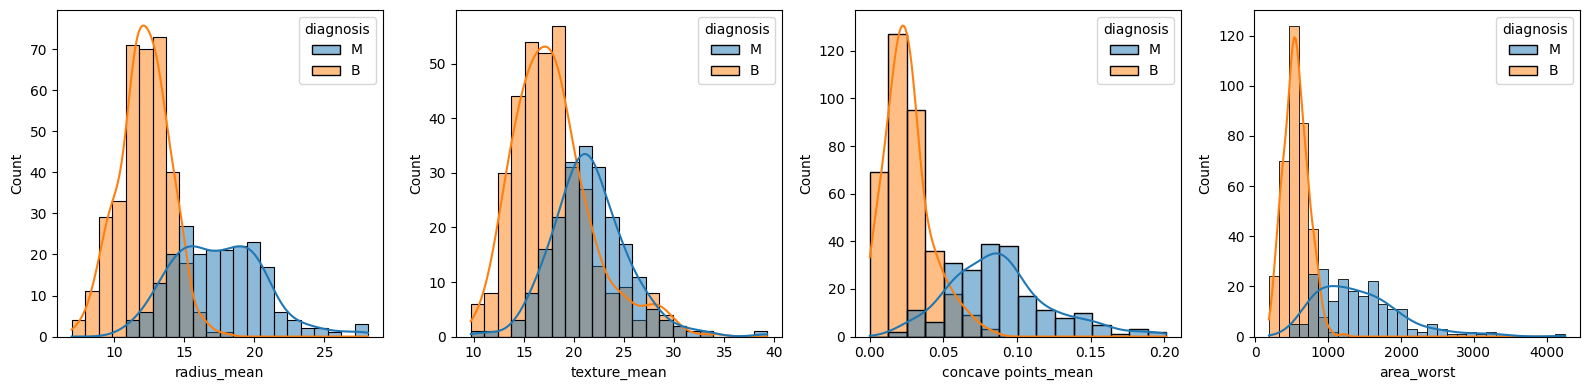

In [6]:
# 4 colunas para ver como os valores se distribuem: tamanho (raio e área), textura e concavidade.
cols = ['radius_mean', 'texture_mean', 'concave points_mean', 'area_worst']  # colunas escolhidas
# subplots(1, 4) cria 1 linha com 4 gráficos. figsize=(16, 4) é o tamanho em polegadas: 16 de largura, 4 de altura.
fig, axes = plt.subplots(1, 4, figsize=(16, 4))                # fig = a figura toda; axes = os 4 gráficos
# zip junta as duas listas em pares: (1º gráfico, 1ª coluna), (2º gráfico, 2ª coluna) e assim por diante.
for ax, col in zip(axes, cols):                                # repete o bloco abaixo para cada par
    # histplot desenha um histograma: barras com quantos pacientes caem em cada faixa de valor.
    # hue='diagnosis' pinta cada classe de uma cor. kde=True acrescenta uma curva suave da distribuição.
    # ax=ax diz em qual dos 4 gráficos desenhar.
    sns.histplot(data=dados, x=col, hue='diagnosis', kde=True, ax=ax)  # histograma por classe
# tight_layout ajusta os espaços, para os títulos e os eixos não ficarem uns por cima dos outros.
plt.tight_layout()                                             # ajusta os espaços
# savefig grava a figura num arquivo PNG, na pasta figuras, para usar no relatório.
plt.savefig('figuras/histogramas.png')                         # salva o gráfico
plt.show()                                                     # mostra o gráfico no notebook

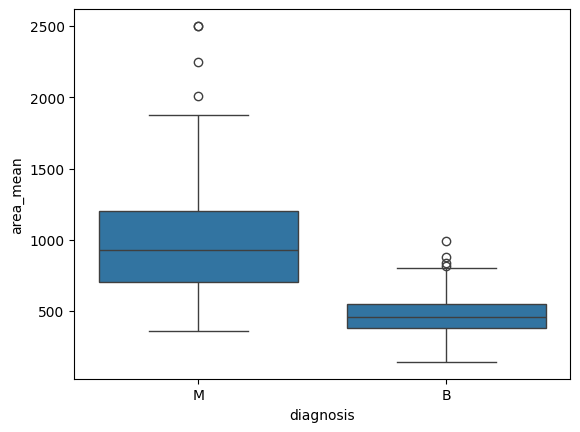

diagnosis              M
radius_mean        27.42
perimeter_mean     186.9
area_mean         2501.0
Name: 461, dtype: object


In [7]:
# boxplot desenha uma caixa por classe. A linha do meio é a mediana; a caixa vai do 1º ao 3º quartil;
# os pontos soltos, fora dos "bigodes", são valores extremos (outliers).
sns.boxplot(data=dados, x='diagnosis', y='area_mean')          # uma caixa para B e outra para M
plt.savefig('figuras/boxplot_area.png')                        # salva o gráfico
plt.show()                                                     # mostra o gráfico
# idxmax devolve a linha do maior valor de area_mean. loc pega essa linha e as colunas escolhidas.
# Raio, perímetro e área grandes ao mesmo tempo: é um tumor grande de verdade, e não um erro de digitação.
print(dados.loc[dados['area_mean'].idxmax(), ['diagnosis', 'radius_mean', 'perimeter_mean', 'area_mean']])  # o maior tumor da base

**O que a exploração mostrou:**

| Achado | Decisão |
| --- | --- |
| 63% benignos e 37% malignos | dividir os dados com `stratify` |
| Malignos têm raio, área e pontos côncavos maiores | as medidas separam bem as classes |
| Escalas muito diferentes (área até 2.501; smoothness perto de 0,1) | padronizar os dados para KNN e SVM |
| Valores extremos são tumores grandes de verdade | manter esses pacientes |

## 3. Limpar e preparar

O modelo só aceita números e não aceita valores vazios. Por isso:

- a coluna `id` sai, porque é só um código;
- a coluna `Unnamed: 32` sai, porque está 100% vazia;
- o alvo vira número com o LabelEncoder (B = 0, M = 1), para que o recall seja calculado para a classe Maligno.

A padronização fica para depois, dentro de um Pipeline, para aprender só com os dados de treino.

In [8]:
# isna() marca com True cada valor vazio (nulo). sum() soma os True de cada coluna: o número de nulos.
nulos = dados.isna().sum()                                     # nulos por coluna
# nulos[nulos > 0] é um filtro: mostra só as colunas com pelo menos 1 nulo.
print(nulos[nulos > 0])                                        # esperado: só 'Unnamed: 32', com 569 nulos (toda vazia)
# drop(columns='id') tira o código do paciente, que é diferente em cada linha e esconderia as repetições.
# duplicated() marca as linhas iguais a uma linha anterior. sum() conta quantas são.
print('Linhas repetidas:', dados.drop(columns='id').duplicated().sum())  # esperado: 0
# drop(columns=[...]) devolve a tabela sem essas colunas. O resultado volta para a variável dados.
dados = dados.drop(columns=['id', 'Unnamed: 32'])              # tira o código do paciente e a coluna vazia
print(dados.shape)                                             # esperado: (569, 31)

Unnamed: 32    569
dtype: int64
Linhas repetidas: 0
(569, 31)


In [9]:
# O LabelEncoder, do scikit-learn, troca texto por número: as categorias viram 0, 1, 2... em ordem alfabética.
from sklearn.preprocessing import LabelEncoder                 # scikit-learn: a biblioteca de Machine Learning
le = LabelEncoder()                                            # cria o codificador, ainda sem saber as categorias
# fit_transform faz 2 coisas: fit aprende as categorias (B e M); transform troca cada uma pelo seu número.
dados['diagnosis'] = le.fit_transform(dados['diagnosis'])      # B vira 0 e M vira 1
# classes_ mostra as categorias na ordem dos números: posição 0 = 'B', posição 1 = 'M'.
print(le.classes_)                                             # esperado: ['B' 'M'], ou seja, maligno = 1
# y é o alvo: o que o modelo deve prever. x são as entradas: as 30 medidas das células.
y = dados['diagnosis']                                         # alvo: 0 = benigno, 1 = maligno
x = dados.drop(columns=['diagnosis'])                          # as 30 colunas de medidas
print(x.shape)                                                 # esperado: (569, 30)
# (x['concavity_mean'] == 0) marca True onde o valor é zero; sum() conta os True.
# Esses zeros são reais (células sem concavidade), não dados faltando. Por isso ficam.
# Os mesmos 13 pacientes, todos benignos, têm zero nas 6 colunas de concavidade.
print('Zeros em concavity_mean:', (x['concavity_mean'] == 0).sum())  # esperado: 13

['B' 'M']
(569, 30)
Zeros em concavity_mean: 13


## 4. Correlação

A correlação mostra quais colunas mais se ligam ao diagnóstico e quais repetem a mesma informação. Vale lembrar que correlação não indica causa.

In [10]:
# corr() calcula a correlação entre todas as colunas, de -1 a 1. Perto de 1: as duas sobem juntas;
# perto de -1: uma sobe e a outra desce; perto de 0: sem relação em linha reta.
# ['diagnosis'] pega só a correlação de cada coluna com o alvo. drop tira o próprio alvo, que daria 1.
# sort_values(ascending=False) ordena do maior para o menor.
corr_alvo = dados.corr()['diagnosis'].drop('diagnosis').sort_values(ascending=False)  # correlação com o diagnóstico
# head(5) pega as 5 primeiras linhas: as 5 maiores correlações.
print(corr_alvo.head(5).round(2))                              # as 5 colunas mais ligadas ao câncer
# abs() tira o sinal (-0,3 vira 0,3). Ordenando do menor para o maior, ficam em cima as mais perto de zero.
print(corr_alvo.abs().sort_values().head(3).round(2))          # as 3 colunas com menos ligação

concave points_worst    0.79
perimeter_worst         0.78
concave points_mean     0.78
radius_worst            0.78
perimeter_mean          0.74
Name: diagnosis, dtype: float64
symmetry_se               0.01
texture_se                0.01
fractal_dimension_mean    0.01
Name: diagnosis, dtype: float64


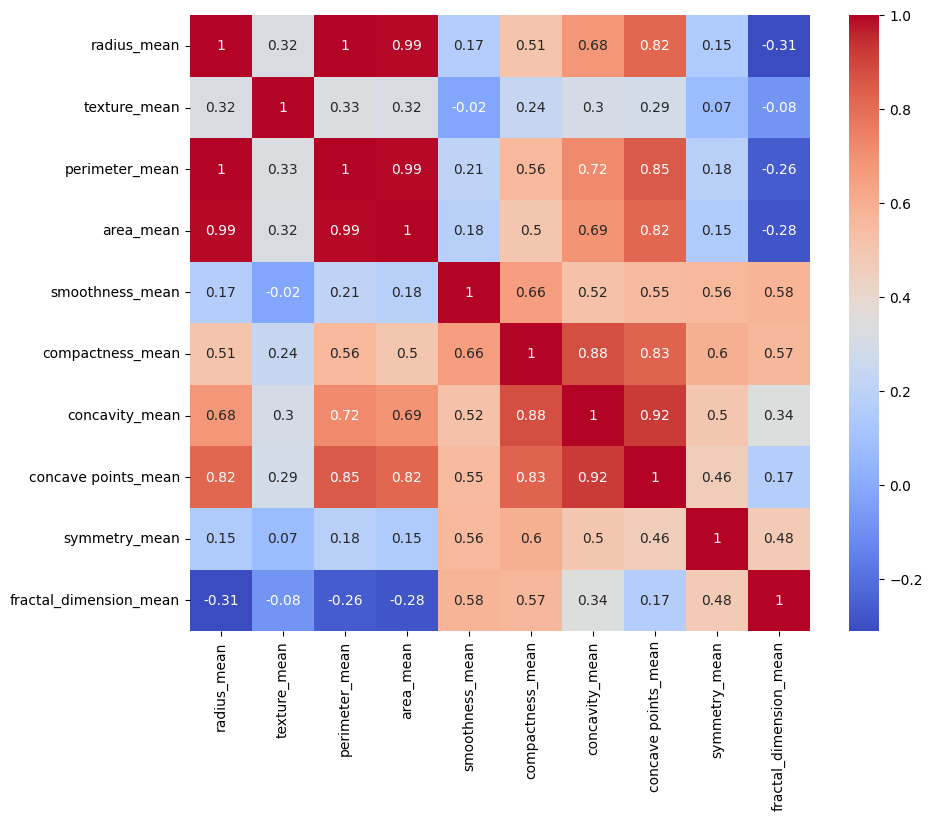

In [11]:
# Esta linha monta uma lista com cada coluna c de x cujo nome termina com '_mean' (list comprehension).
cols_mean = [c for c in x.columns if c.endswith('_mean')]      # as 10 colunas de média
plt.figure(figsize=(10, 8))                                    # nova figura, com 10 x 8 polegadas
# heatmap pinta cada quadrado de uma tabela com uma cor. annot=True escreve o número dentro do quadrado.
# cmap='coolwarm' usa azul para valores negativos e vermelho para positivos. round(2) deixa os números curtos.
sns.heatmap(x[cols_mean].corr().round(2), annot=True, cmap='coolwarm')  # mapa de calor da correlação
# bbox_inches='tight' corta as bordas brancas e não deixa os nomes das colunas cortados na imagem.
plt.savefig('figuras/correlacao_mean.png', bbox_inches='tight')  # salva o gráfico
plt.show()                                                     # mostra o gráfico

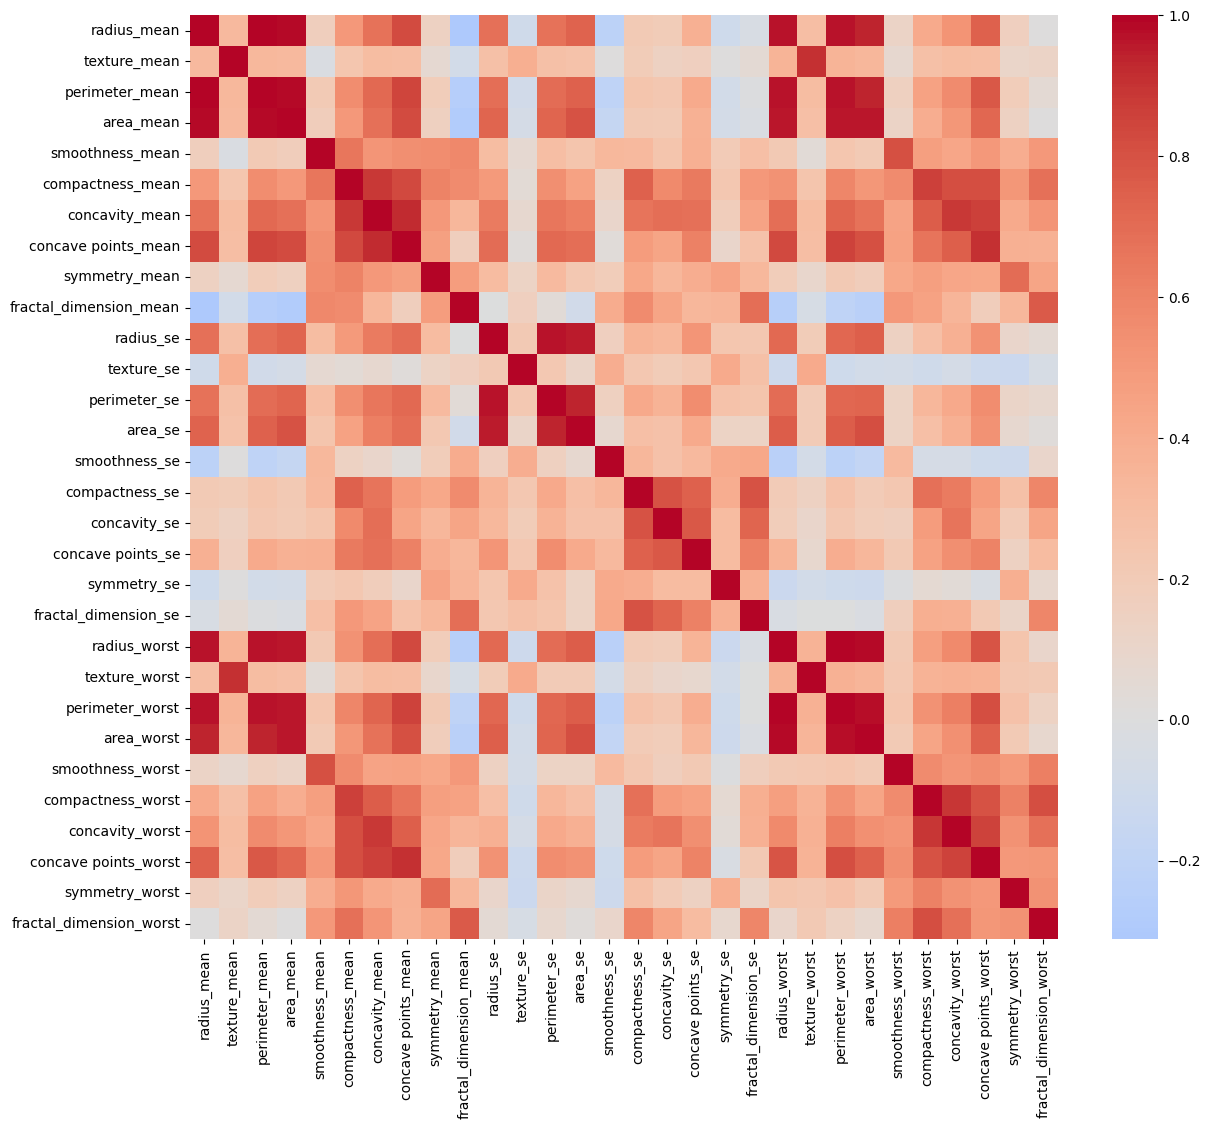

In [12]:
plt.figure(figsize=(14, 12))                                   # figura maior: agora são 30 colunas
# Aqui não há annot: com 30 x 30 quadrados, os números ficariam pequenos demais para ler.
# center=0 põe o zero na cor clara do meio, separando correlações positivas (vermelho) e negativas (azul).
sns.heatmap(x.corr(), cmap='coolwarm', center=0)               # mapa de calor das 30 colunas
plt.savefig('figuras/correlacao_todas.png', bbox_inches='tight')  # salva o gráfico
plt.show()                                                     # mostra o gráfico

In [13]:
# abs() tira o sinal: para achar colunas repetidas, tanto faz se a relação é positiva ou negativa.
c = x.corr().abs()                                             # tabela 30 x 30 de correlações, sem sinal
# Esta lista guarda os pares de colunas com correlação acima de 0,9, no formato (coluna 1, coluna 2, valor).
# c.loc[a, b] lê o valor da linha a e da coluna b. float e round(..., 3) deixam um número simples, com 3 casas.
pares = [(a, b, round(float(c.loc[a, b]), 3))                  # cada par encontrado
         # enumerate dá a posição i de cada coluna a.
         for i, a in enumerate(c.columns)                      # percorre as colunas
         # c.columns[i + 1:] pega só as colunas depois de a. Assim, o par a-b não é contado de novo como b-a.
         for b in c.columns[i + 1:]                            # percorre as colunas seguintes
         # 0,9 é um limite comum para dizer que duas colunas carregam quase a mesma informação.
         if c.loc[a, b] > 0.9]                                 # fica só o par acima de 0,9
# len conta os itens de uma lista.
print('Pares acima de 0,9:', len(pares))                       # esperado: 21
# sorted ordena a lista. key=lambda p: -p[2] ordena pelo valor (3º item do par), do maior para o menor.
# [:3] pega os 3 primeiros.
print(sorted(pares, key=lambda p: -p[2])[:3])                  # os 3 pares mais parecidos; o 1º é raio x perímetro, com 0,998

Pares acima de 0,9: 21
[('radius_mean', 'perimeter_mean', 0.998), ('radius_worst', 'perimeter_worst', 0.994), ('radius_mean', 'area_mean', 0.987)]


## 5. Treino, validação e teste

O modelo precisa ser medido com pacientes que ele nunca viu. Por isso, os dados têm três papéis:

| Parte | Linhas | Para quê |
| --- | --- | --- |
| Teste | 114 (20%) | fica guardado e só é usado no fim, depois de todas as escolhas |
| Treino | 455 (80%) | o modelo aprende |
| Validação | dentro do treino | validação cruzada em 5 partes (KFold), para comparar modelos |

O KFold sorteia as 5 partes sem olhar a classe. Por isso, a proporção de malignos muda um pouco de uma parte para outra (a célula abaixo mostra). Essa variação entra no desvio entre as rodadas.

In [14]:
# train_test_split sorteia quais linhas vão para o treino e quais vão para o teste.
# KFold divide o treino em partes, para a validação cruzada.
from sklearn.model_selection import train_test_split, KFold    # ferramentas de divisão dos dados
x_train, x_test, y_train, y_test = train_test_split(           # devolve 4 partes: entradas e alvo, de treino e de teste
    x, y,                                                      # as entradas e o alvo
    test_size=0.2,                                             # 20% das linhas vão para o teste (114 pacientes)
    # stratify=y mantém a mesma proporção de malignos (37%) no treino e no teste.
    stratify=y,                                                # sem isso, o sorteio poderia deixar o teste com poucos malignos
    # random_state fixa o sorteio: com o mesmo número, a divisão sai igual toda vez. O 42 é só uma convenção.
    random_state=42)                                           # resultados repetíveis
# KFold(n_splits=5) divide o treino em 5 partes. Em cada uma das 5 rodadas, 4 partes treinam e 1 valida.
# shuffle=True embaralha as linhas antes de dividir; random_state=42 fixa esse embaralhamento.
kfold = KFold(n_splits=5, shuffle=True, random_state=42)       # a validação cruzada
print(x_train.shape, x_test.shape)                             # esperado: (455, 30) (114, 30)
# y_test tem 0 e 1. A soma conta os 1, ou seja, os malignos do teste.
print('Malignos no teste:', y_test.sum())                      # esperado: 42
# split devolve as posições de treino e de validação de cada rodada; v são as de validação.
# mean dá a proporção de malignos (1) nessa parte. float e round deixam um número simples, com 2 casas.
print('Malignos em cada parte:', [round(float(y_train.iloc[v].mean()), 2) for _, v in kfold.split(x_train)])  # esperado: de 0.33 a 0.43

(455, 30) (114, 30)
Malignos no teste: 42
Malignos em cada parte: [0.35, 0.43, 0.33, 0.42, 0.34]


## 6. Comparar 4 modelos

Comparamos quatro modelos de classificação na validação, sem tocar no teste. KNN e SVM usam distâncias e precisam de dados na mesma escala, então vão num Pipeline com StandardScaler. A Árvore e o Random Forest não precisam de escala.

In [15]:
from sklearn.pipeline import Pipeline                          # Pipeline: junta etapas (escala + modelo) num só objeto
from sklearn.preprocessing import StandardScaler               # StandardScaler: deixa cada coluna com média 0 e desvio padrão 1
from sklearn.neighbors import KNeighborsClassifier             # KNN: decide pela classe dos pacientes mais parecidos
from sklearn.svm import SVC                                    # SVM: procura a fronteira com a maior margem entre as classes
from sklearn.tree import DecisionTreeClassifier                # Árvore de Decisão: regras do tipo "se / senão"
from sklearn.ensemble import RandomForestClassifier            # Random Forest: o voto de muitas árvores
from sklearn.model_selection import cross_val_score            # cross_val_score: mede um modelo na validação cruzada

# Dicionário {nome: modelo}. Os modelos ainda não foram treinados e usam os ajustes padrão.
# No Pipeline, a escala aprende a média e o desvio só com as partes de treino de cada rodada.
# Isso evita vazamento: a parte de validação nunca influencia a padronização.
# random_state=42 fixa os sorteios internos do modelo, para o resultado se repetir.
modelos = {                                                    # os 4 modelos
    'KNN': Pipeline([('escala', StandardScaler()), ('modelo', KNeighborsClassifier())]),  # KNN usa distâncias: precisa de escala
    'SVM': Pipeline([('escala', StandardScaler()), ('modelo', SVC(random_state=42))]),  # SVM também usa distâncias: precisa de escala
    'Árvore': DecisionTreeClassifier(random_state=42),         # olha uma coluna por vez: não precisa de escala
    'Random Forest': RandomForestClassifier(random_state=42),  # feito de árvores: também não precisa
}                                                              # fim do dicionário

linhas = []                                                    # lista vazia: vai guardar uma linha de resultado por modelo
# items() devolve os pares (nome, modelo) do dicionário.
for nome, modelo in modelos.items():                           # repete o bloco abaixo para cada modelo
    # cross_val_score treina e mede o modelo 5 vezes (cv=kfold) e devolve as 5 notas.
    # scoring escolhe a métrica: 'recall', 'f1' ou 'accuracy'. Usa só o treino; o teste fica guardado.
    recall = cross_val_score(modelo, x_train, y_train, cv=kfold, scoring='recall')  # recall nas 5 rodadas
    f1 = cross_val_score(modelo, x_train, y_train, cv=kfold, scoring='f1')  # F1 nas 5 rodadas
    acuracia = cross_val_score(modelo, x_train, y_train, cv=kfold, scoring='accuracy')  # acurácia nas 5 rodadas
    # append acrescenta um item à lista. mean() é a média das 5 notas.
    # std() é o desvio padrão: mostra quanto a nota muda de uma rodada para outra.
    linhas.append({'modelo': nome,                             # nome do modelo
                   'recall': recall.mean(),                    # média do recall
                   'recall_desvio': recall.std(),              # variação do recall entre as rodadas
                   'f1': f1.mean(),                            # média do F1
                   'acuracia': acuracia.mean()})               # média da acurácia
# DataFrame transforma a lista em tabela. set_index('modelo') usa o nome como rótulo de cada linha.
# round(3) deixa 3 casas decimais, o bastante para comparar os modelos.
resultado = pd.DataFrame(linhas).set_index('modelo').round(3)  # tabela de resultados
# sort_values ordena do maior recall para o menor. Por ser a última linha da célula, o Colab mostra a tabela.
resultado.sort_values('recall', ascending=False)               # o maior recall em cima

,recall,recall_desvio,f1,acuracia
modelo,,,,
SVM,0.942,0.035,0.951,0.963
Random Forest,0.933,0.051,0.943,0.958
Árvore,0.922,0.045,0.918,0.938
KNN,0.911,0.041,0.944,0.960


**Leitura:** SVM e Random Forest lideram, e a diferença entre eles é menor que a variação entre as rodadas. É um empate técnico, então os dois vão para o ajuste. O KNN tem boa acurácia, mas o pior recall: um bom exemplo de que a acurácia sozinha engana.

### Teste extra: o PCA ajuda?

A base tem 21 pares de colunas que repetem informação. O PCA junta essas colunas em poucos componentes. Testamos se isso melhora o SVM.

In [16]:
from sklearn.decomposition import PCA                          # PCA: resume muitas colunas parecidas em poucas componentes
# Pipeline com 3 etapas, nesta ordem: escala, PCA e SVM. O PCA precisa da escala antes;
# sem ela, as colunas com números grandes (como a área) dominariam as componentes.
svm_pca = Pipeline([('escala', StandardScaler()),              # 1ª etapa: padronização
                    # n_components=0.95: o PCA guarda as componentes necessárias para manter 95% da informação (variância).
                    ('pca', PCA(n_components=0.95)),           # 2ª etapa: redução de colunas
                    ('modelo', SVC(random_state=42))])         # 3ª etapa: o mesmo SVM de antes, para a comparação ser justa
recall_pca = cross_val_score(svm_pca, x_train, y_train, cv=kfold, scoring='recall').mean()  # recall médio com PCA, nas mesmas 5 rodadas
# fit treina o Pipeline com todo o treino. Aqui, serve só para descobrir quantas componentes o PCA escolheu.
svm_pca.fit(x_train, y_train)                                  # treina
# named_steps['pca'] pega a etapa do PCA dentro do Pipeline. n_components_ é o número de componentes escolhido.
print('Componentes:', svm_pca.named_steps['pca'].n_components_)  # esperado: 10 (eram 30 colunas)
print('Recall do SVM com PCA:', round(recall_pca, 3))          # esperado: 0,942, igual ao SVM sem PCA

Componentes: 10
Recall do SVM com PCA: 0.942


**Decisão:** o modelo final **não** usa PCA. O recall ficou igual, e as colunas originais são mais fáceis de explicar ao médico.

## 7. Ajustar os 2 melhores (GridSearch)

O GridSearchCV testa todas as combinações de hiperparâmetros, cada uma com validação cruzada. O critério de escolha é o recall.

In [17]:
from sklearn.model_selection import GridSearchCV               # GridSearchCV: testa combinações de ajustes com validação cruzada
# A grade é um dicionário: cada ajuste (hiperparâmetro) e a lista de valores a testar.
# 'modelo__C' quer dizer: o ajuste C da etapa chamada 'modelo' no Pipeline. Os 2 sublinhados separam os nomes.
grade_svm = {'modelo__C': [0.1, 1, 10, 100],                   # C: quanto o SVM pune erros no treino; C alto = margem mais estreita
             'modelo__kernel': ['linear', 'rbf'],              # kernel: fronteira reta (linear) ou curva (rbf)
             # class_weight='balanced' dá mais peso aos erros na classe menor (maligno); None = peso igual.
             'modelo__class_weight': [None, 'balanced']}       # peso das classes
# cv=kfold usa as mesmas 5 rodadas. scoring com 2 métricas: o GridSearchCV mede o recall e a precisão de cada combinação.
# refit='recall' faz vencer a combinação com maior recall. A precisão é a conferência: um modelo que
# chamasse todos de malignos teria recall 1,0, mas precisão baixa.
# n_jobs=-1 usa todos os núcleos do processador, para terminar mais rápido.
grid_svm = GridSearchCV(modelos['SVM'], grade_svm, cv=kfold, scoring={'recall': 'recall', 'precisao': 'precision'}, refit='recall', n_jobs=-1)  # 4 x 2 x 2 = 16 combinações
grid_svm.fit(x_train, y_train)                                 # treina 16 combinações x 5 rodadas = 80 vezes, só com o treino
print(grid_svm.best_params_)                                   # best_params_: a melhor combinação. Esperado: C=10, rbf, balanced
print('Recall:', round(grid_svm.best_score_, 3))               # best_score_: o recall médio dela (a métrica do refit). Esperado: 0,959
# cv_results_ guarda os resultados de todas as combinações, e best_index_ é a posição da melhor.
# std_test_recall é o desvio do recall; mean_test_precisao é a precisão média.
print('Desvio:', round(grid_svm.cv_results_['std_test_recall'][grid_svm.best_index_], 3))  # esperado: 0,015
print('Precisão:', round(grid_svm.cv_results_['mean_test_precisao'][grid_svm.best_index_], 3))  # precisão da combinação vencedora

{'modelo__C': 10, 'modelo__class_weight': 'balanced', 'modelo__kernel': 'rbf'}
Recall: 0.959
Desvio: 0.015
Precisão: 0.965


In [18]:
# Aqui não há "modelo__" nos nomes, porque o Random Forest não está dentro de um Pipeline.
grade_rf = {'n_estimators': [100, 300],                        # n_estimators: número de árvores na floresta
            # max_depth: quantos níveis de perguntas cada árvore pode ter. None = sem limite.
            # Limitar a profundidade ajuda contra o overfitting (decorar o treino).
            'max_depth': [None, 5, 10],                        # profundidade máxima
            'class_weight': [None, 'balanced']}                # peso das classes, como no SVM
# As mesmas 2 métricas do SVM: vence o maior recall, e a precisão serve de conferência.
grid_rf = GridSearchCV(modelos['Random Forest'], grade_rf, cv=kfold, scoring={'recall': 'recall', 'precisao': 'precision'}, refit='recall', n_jobs=-1)  # 2 x 3 x 2 = 12 combinações
grid_rf.fit(x_train, y_train)                                  # treina 12 combinações x 5 rodadas = 60 vezes
print(grid_rf.best_params_)                                    # esperado: None, None, 300
print('Recall:', round(grid_rf.best_score_, 3))                # esperado: 0,938
print('Desvio:', round(grid_rf.cv_results_['std_test_recall'][grid_rf.best_index_], 3))  # esperado: 0,042
print('Precisão:', round(grid_rf.cv_results_['mean_test_precisao'][grid_rf.best_index_], 3))  # precisão da combinação vencedora

{'class_weight': None, 'max_depth': None, 'n_estimators': 300}
Recall: 0.938
Desvio: 0.042
Precisão: 0.957


**Modelo final: Random Forest.** O SVM teve recall um pouco maior (0,959 contra 0,938) e variou menos entre as rodadas (0,015 contra 0,042). A diferença média, porém, é de só 0,021: menos de 1 câncer por rodada, já que cada parte da validação tem cerca de 34 malignos. Escolhemos o Random Forest porque ele mostra de forma direta quais colunas pesam na decisão, o que ajuda o médico a confiar no modelo. A escolha é feita **antes** de olhar o teste.

## 8. Avaliar no teste

O teste mostra como o modelo se sai com pacientes novos. Por isso, ele só é usado agora, no fim, depois de todas as escolhas. Olhamos a matriz de confusão, o recall, a precisão, o F1 e a curva ROC. O SVM e a árvore pequena também são medidos no teste, só para registro: isso não muda a escolha.

              precision    recall  f1-score   support

     Benigno      0.960     1.000     0.980        72
     Maligno      1.000     0.929     0.963        42

    accuracy                          0.974       114
   macro avg      0.980     0.964     0.971       114
weighted avg      0.975     0.974     0.973       114



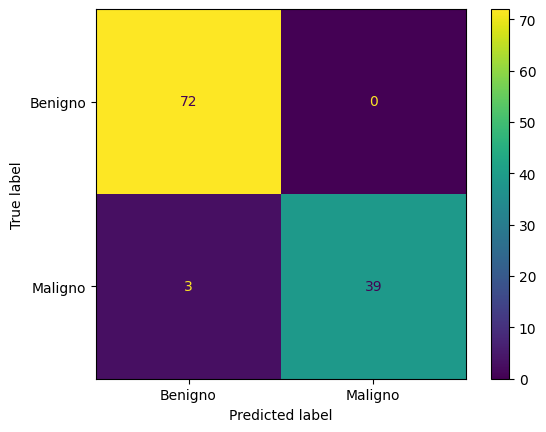

In [19]:
# classification_report: tabela com precisão, recall e F1 de cada classe.
# confusion_matrix conta os acertos e os erros; ConfusionMatrixDisplay desenha essa contagem.
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay  # métricas do teste
# best_estimator_ é o modelo com a melhor combinação, que o GridSearchCV já treinou de novo com todo o treino.
final = grid_rf.best_estimator_                                # o modelo escolhido: o Random Forest ajustado
svm_final = grid_svm.best_estimator_                           # o SVM ajustado, só para comparar
# predict devolve a classe prevista (0 ou 1) de cada paciente. É a primeira vez que o teste é usado.
y_pred = final.predict(x_test)                                 # previsões no teste
# target_names dá nome às classes 0 e 1. digits=3 mostra 3 casas decimais.
print(classification_report(y_test, y_pred, target_names=['Benigno', 'Maligno'], digits=3))  # métricas por classe
mc = confusion_matrix(y_test, y_pred)                          # tabela 2 x 2: linhas = classe real, colunas = classe prevista
# plot desenha a matriz. values_format='d' mostra os números como inteiros (72, e não 7.2e+01).
ConfusionMatrixDisplay(confusion_matrix=mc, display_labels=['Benigno', 'Maligno']).plot(values_format='d')  # desenha a matriz
plt.savefig('figuras/matriz_confusao.png')                     # salva o gráfico
plt.show()                                                     # mostra o gráfico

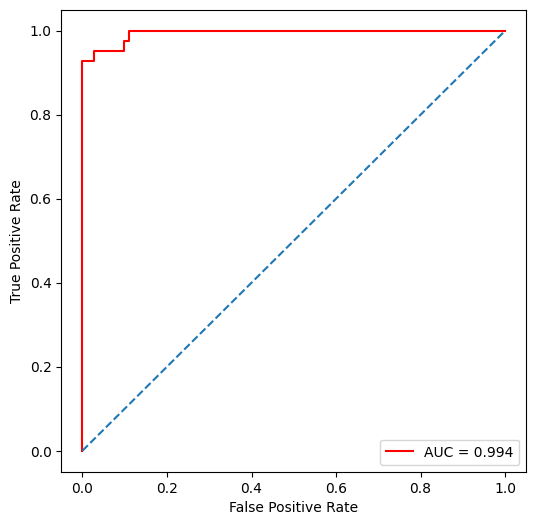

In [20]:
# roc_curve calcula os pontos da curva ROC; auc calcula a área sob essa curva (AUC).
from sklearn.metrics import roc_curve, auc                     # curva ROC e AUC
# predict_proba devolve 2 colunas: a chance de ser benigno (coluna 0) e a de ser maligno (coluna 1).
# [:, 1] pega todas as linhas (:) da coluna 1.
y_prob = final.predict_proba(x_test)[:, 1]                     # chance de cada paciente ser maligno
# Para cada limiar possível, roc_curve calcula a taxa de falsos positivos (fpr) e a de verdadeiros positivos (tpr).
fpr, tpr, limiares = roc_curve(y_test, y_prob)                 # pontos da curva
# A AUC vai de 0,5 (um chute) a 1 (separação perfeita).
roc_auc = auc(fpr, tpr)                                        # área sob a curva
plt.figure(figsize=(6, 6))                                     # figura quadrada
# '%0.3f' % roc_auc escreve o número com 3 casas decimais na legenda.
plt.plot(fpr, tpr, color='red', label='AUC = %0.3f' % roc_auc)  # a curva ROC, em vermelho
# Linha tracejada (linestyle='--') do ponto (0, 0) ao (1, 1): o resultado de um chute ao acaso.
plt.plot([0, 1], [0, 1], linestyle='--')                       # referência do chute
plt.xlabel('False Positive Rate')                              # eixo x: taxa de falsos positivos
plt.ylabel('True Positive Rate')                               # eixo y: taxa de verdadeiros positivos (o recall)
plt.legend(loc='lower right')                                  # legenda no canto de baixo, à direita
plt.savefig('figuras/curva_roc.png')                           # salva o gráfico
plt.show()                                                     # mostra o gráfico

In [21]:
# tolist() transforma a matriz em lista, para caber numa linha: [[VN, FP], [FN, VP]].
# V = verdadeiro, F = falso, N = negativo (benigno), P = positivo (maligno).
print('SVM no teste:', confusion_matrix(y_test, svm_final.predict(x_test)).tolist())  # esperado: igual à do Random Forest
# score devolve a acurácia do modelo nos dados que recebe. No treino, ela mostra se o modelo decorou.
print('Acurácia no treino:', round(final.score(x_train, y_train), 3))  # esperado: 1,0, porque cada árvore cresce até o fim
acc_val = cross_val_score(final, x_train, y_train, cv=kfold, scoring='accuracy').mean()  # acurácia média na validação cruzada
print('Acurácia na validação:', round(acc_val, 3))             # esperado: 0,96
# Se o teste ficar perto da validação, o modelo generaliza: vai bem com pacientes que nunca viu.
print('Acurácia no teste:', round(final.score(x_test, y_test), 3))  # esperado: 0,974

SVM no teste: [[72, 0], [3, 39]]
Acurácia no treino: 1.0


Acurácia na validação: 0.96
Acurácia no teste: 0.974


## 9. Interpretar

O médico precisa entender por que o modelo decide. Usamos três ferramentas:

- a importância das variáveis do Random Forest, que mede quanto cada coluna ajudou a separar as classes no modelo todo;
- uma árvore pequena, desenhada, que mostra regras de decisão parecidas com as do modelo;
- o SHAP, que mostra a direção de cada coluna e explica a decisão de cada paciente (explicado antes das células dele).

perimeter_worst         0.143
area_worst              0.142
concave points_worst    0.113
concave points_mean     0.089
radius_worst            0.083
dtype: float64


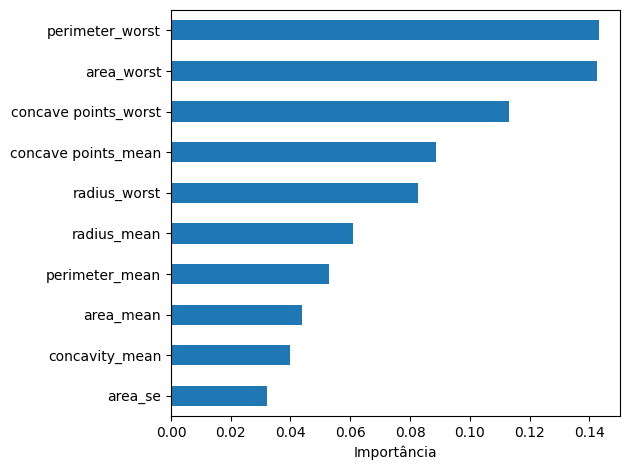

In [22]:
# feature_importances_ é a importância de cada coluna no Random Forest treinado: quanto ela ajudou
# a separar as classes, na média de todas as árvores. Os 30 valores somam 1.
# pd.Series cria uma lista com rótulos (o nome de cada coluna). sort_values ordena do menor para o maior.
importancia = pd.Series(final.feature_importances_, index=x.columns).sort_values()  # importância de cada coluna
# tail(5) pega as 5 últimas, que são as maiores. sort_values(ascending=False) põe a maior em cima.
print(importancia.tail(5).sort_values(ascending=False).round(3))  # as 5 colunas que mais pesam
# plot.barh desenha barras horizontais. Como a lista está em ordem crescente, a maior barra fica no topo.
importancia.tail(10).plot.barh()                               # gráfico das 10 maiores
plt.xlabel('Importância')                                      # nome do eixo x
plt.tight_layout()                                             # ajusta os espaços, para os nomes das colunas caberem
plt.savefig('figuras/feature_importance.png')                  # salva o gráfico
plt.show()                                                     # mostra o gráfico

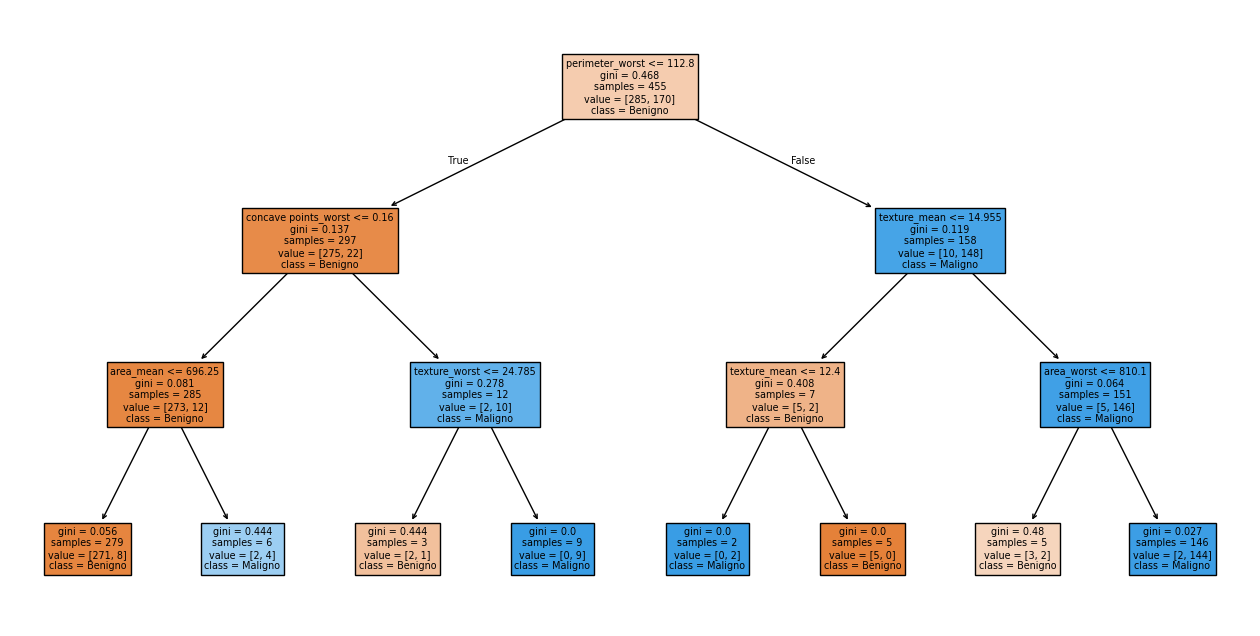

Árvore pequena: acurácia 0.904 | recall 0.786


In [23]:
from sklearn.tree import plot_tree                             # plot_tree: desenha uma árvore de decisão treinada
# accuracy_score e recall_score calculam a acurácia e o recall a partir das respostas reais e das previstas.
from sklearn.metrics import accuracy_score, recall_score       # métricas
# max_depth=3: só 3 níveis de perguntas, para a árvore caber na figura e dar para ler.
arvore = DecisionTreeClassifier(max_depth=3, random_state=42)  # árvore pequena, feita só para explicar
arvore.fit(x_train, y_train)                                   # treina com o treino
fig, ax = plt.subplots(figsize=(16, 8))                        # figura larga: a árvore se abre para os lados
plot_tree(arvore,                                              # a árvore treinada
          feature_names=list(x.columns),                       # nomes das colunas, para as perguntas ficarem legíveis
          class_names=['Benigno', 'Maligno'],                  # na ordem dos rótulos: 0 = Benigno, 1 = Maligno
          # filled=True pinta cada caixa com a cor da classe que vence nela. ax=ax desenha na figura criada acima.
          filled=True, ax=ax)                                  # cores e lugar do desenho
plt.savefig('figuras/arvore.png', bbox_inches='tight')         # salva sem cortar as bordas
plt.show()                                                     # mostra o gráfico
p_arvore = arvore.predict(x_test)                              # previsões da árvore pequena no teste
# Mede a árvore pequena no teste. Ela é pior que o Random Forest: serve para explicar, não para diagnosticar.
print('Árvore pequena: acurácia', round(accuracy_score(y_test, p_arvore), 3), '| recall', round(recall_score(y_test, p_arvore), 3))  # esperado: 0,904 e 0,786

### SHAP: o que pesou para cada paciente

A importância das variáveis da célula anterior dá **um número por coluna para o modelo todo**. Ela tem três limites:

- não diz a **direção**: mostra que o perímetro pesa, mas não se um perímetro alto empurra para maligno ou para benigno;
- não explica **um paciente**: o médico quer saber por que *aquele* exame deu maligno;
- **se divide** entre colunas que repetem informação, como raio, perímetro e área.

O **SHAP** (Lundberg e Lee, 2017) resolve os dois primeiros. Para cada paciente, ele parte da chance média de câncer do modelo e mostra quanto cada coluna somou ou tirou até chegar à chance daquele paciente. Valor positivo empurra para maligno; negativo, para benigno. O enunciado também pede o SHAP.

O terceiro limite continua: no SHAP, colunas que repetem informação também dividem o peso entre si. Por isso, lemos os grupos de colunas (tamanho e concavidade), e não cada coluna sozinha.

Usamos dois gráficos: o **resumo** (todos os pacientes do teste de uma vez) e a **cascata** de um dos 3 cânceres que o modelo deixou passar, para entender o erro mais grave.

area_worst              0.067
perimeter_worst         0.060
concave points_worst    0.059
concave points_mean     0.044
radius_worst            0.042
dtype: float64


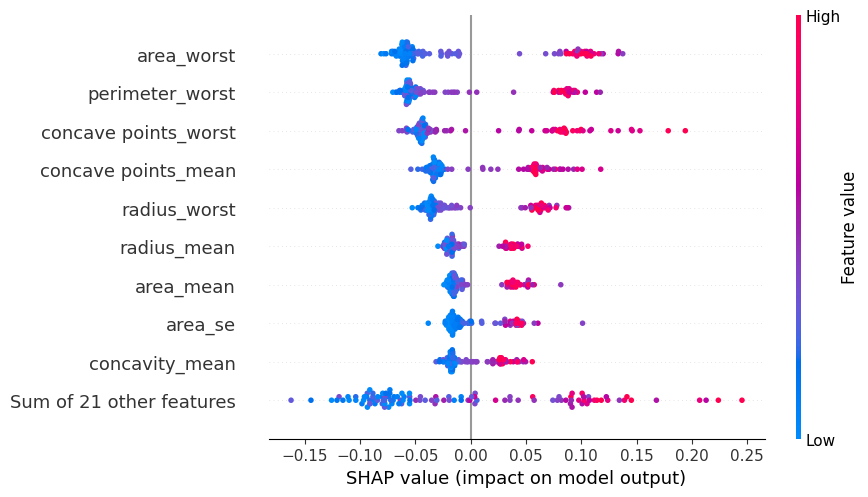

In [24]:
# "!" roda um comando do terminal. O pip instala o SHAP; se ele já estiver instalado (o Colab costuma ter), não faz nada.
!pip install -q shap                                           # instala o SHAP, se precisar
import shap                                                    # SHAP: explica cada previsão, coluna por coluna
# TreeExplainer é o explicador do SHAP feito para modelos de árvore, como o Random Forest.
# Ele calcula os valores exatos, e rápido, usando a estrutura das próprias árvores.
explicador = shap.TreeExplainer(final)                         # explicador do modelo final
# Chamar o explicador com os pacientes do teste devolve os valores SHAP: um número por paciente e por coluna.
valores = explicador(x_test)                                   # valores SHAP dos 114 pacientes do teste
# O Random Forest tem 2 saídas: chance de benigno e chance de maligno. Por isso, os valores podem vir com
# uma 3ª dimensão, uma por saída. [:, :, 1] pega todos os pacientes, todas as colunas e só a saída 1 (Maligno).
if len(valores.shape) == 3:                                    # 3 dimensões: pacientes x colunas x saídas?
    valores = valores[:, :, 1]                                 # fica só com a saída "maligno"
# valores.values é a tabela de números SHAP (pacientes x colunas) guardada dentro do resultado.
# np.abs tira o sinal e mean(axis=0) faz a média por coluna: quanto cada coluna pesa, em média, na decisão.
peso_medio = pd.Series(np.abs(valores.values).mean(axis=0), index=x.columns).sort_values(ascending=False)  # peso médio de cada coluna
print(peso_medio.head(5).round(3))                             # as 5 colunas que mais pesam pelo SHAP
# beeswarm (enxame): cada ponto é um paciente. A posição mostra quanto a coluna empurrou a decisão:
# para a direita, maligno; para a esquerda, benigno. A cor mostra o valor da coluna: vermelho = alto, azul = baixo.
# max_display=10 mostra as 10 colunas que mais pesam. show=False deixa o gráfico aberto para salvar antes de mostrar.
shap.plots.beeswarm(valores, max_display=10, show=False)       # gráfico de resumo
plt.savefig('figuras/shap_resumo.png', bbox_inches='tight')    # salva o gráfico
plt.show()                                                     # mostra o gráfico

Cânceres perdidos (posição no teste): [16 24 42]
Chance de maligno dada pelo modelo: 0.16


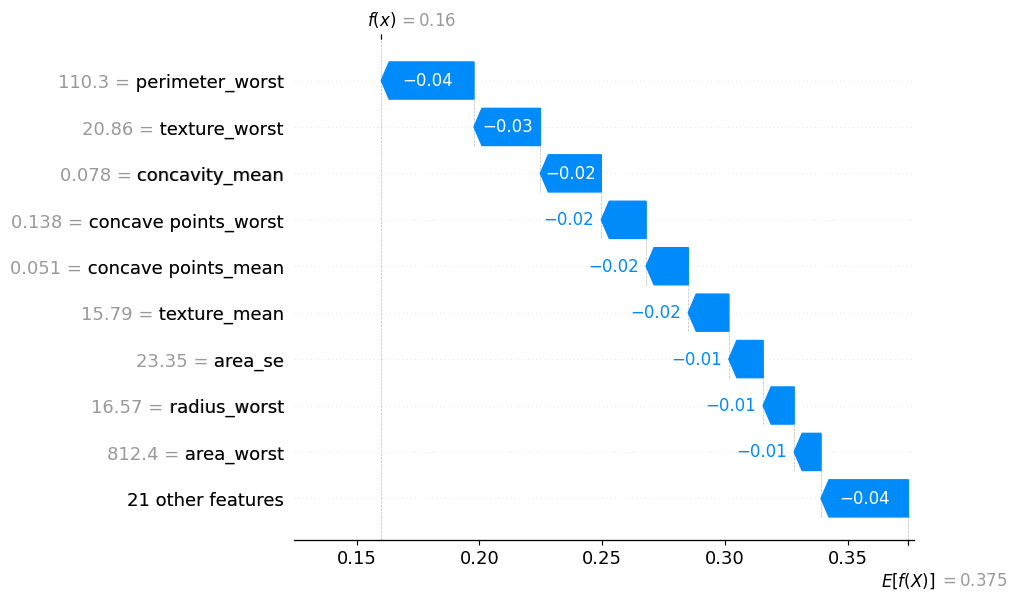

In [25]:
# Os cânceres perdidos são os pacientes malignos (y_test == 1) que o modelo chamou de benignos (y_pred == 0).
# .values tira os rótulos do pandas, para comparar com y_pred, que é uma lista do NumPy. & quer dizer "e".
# np.where devolve as posições numa tupla; o [0] tira a lista de posições de dentro dela.
perdidos = np.where((y_test.values == 1) & (y_pred == 0))[0]   # posições dos falsos negativos no teste
print('Cânceres perdidos (posição no teste):', perdidos)       # esperado: 3 posições
if len(perdidos) > 0:                                          # só desenha se houver algum câncer perdido
    j = perdidos[0]                                            # o 1º câncer perdido
    # iloc[[j]] pega a linha j da tabela (os colchetes duplos mantêm o formato de tabela).
    print('Chance de maligno dada pelo modelo:', round(final.predict_proba(x_test.iloc[[j]])[0, 1], 2))  # abaixo de 0,5 = benigno
    # waterfall (cascata) explica um paciente. Começa embaixo, em E[f(X)]: a chance média de maligno do modelo.
    # Cada barra soma (vermelha, para maligno) ou tira (azul, para benigno) a contribuição de uma coluna,
    # até chegar em f(x), a chance deste paciente. Ao lado de cada coluna aparece o valor dela neste paciente.
    shap.plots.waterfall(valores[j], max_display=10, show=False)  # cascata do 1º câncer perdido
    plt.savefig('figuras/shap_cancer_perdido.png', bbox_inches='tight')  # salva o gráfico
    plt.show()                                                 # mostra o gráfico

**Leitura:** dois grupos de colunas dominam: **tamanho** (perímetro, área e raio) e **concavidade** (pontos côncavos). As ferramentas concordam: as 5 colunas que mais pesam pelo SHAP são as mesmas 5 da importância das variáveis, só em outra ordem. Perímetro, área e raio aparecem juntos nas duas: é o peso dividido entre colunas que repetem informação. O SHAP mostra também a direção: valores altos dessas colunas (pontos vermelhos) empurram para maligno, e valores baixos (pontos azuis), para benigno. Isso bate com a correlação e faz sentido médico.

No câncer perdido da cascata, o modelo deu 16% de chance de maligno, abaixo do limiar de 50%. Quase todas as colunas puxaram para benigno, porque as medidas desse paciente estavam mais perto das de um tumor benigno. O raio médio, por exemplo, é 13,8: mais perto da média dos benignos (12,15) do que da dos malignos (17,46). Na cascata, o `perimeter_worst` dele é 110,3: abaixo do corte de 112,8 da primeira pergunta da árvore pequena. É um caso de fronteira, e por isso um resultado "benigno" nunca dispensa o exame do médico.

A árvore pequena serve para explicar, não para diagnosticar: sozinha, ela acha só 79% dos cânceres.

## 10. O limiar de decisão: cânceres perdidos × alarmes falsos

O modelo não diz só "maligno" ou "benigno": ele dá uma **chance de câncer** para cada paciente. Até aqui, quem tinha chance de 0,5 ou mais virava "maligno". Esse corte é o **limiar**.

Os 3 cânceres perdidos tiveram chance abaixo de 0,5. Baixar o limiar pega mais cânceres, mas também chama mais benignos de malignos: são os **alarmes falsos**. Não dá para ganhar dos dois lados ao mesmo tempo. É uma troca, e esta seção mostra o tamanho dela.

**Por que um câncer perdido pesa mais que um alarme falso?** O câncer perdido pode atrasar o tratamento. O alarme falso leva a mais exames, como uma biópsia, além de ansiedade e custo, mas o erro é corrigido depois.

**Como escolher o limiar sem trapacear:** o limiar não pode ser escolhido olhando o teste. Seria ajustar o modelo aos 42 cânceres do teste, e o resultado ficaria otimista. Por isso:

1. A validação cruzada dá uma chance para cada paciente do treino. Ela é sempre calculada por um modelo que não viu aquele paciente.
2. Com essas chances, achamos o limiar que atinge cada meta de recall: 98%, 99% e 100% dos cânceres do treino.
3. Só depois aplicamos cada limiar ao teste, para conferir.

Uma ressalva: na validação cruzada, cada chance vem de um modelo treinado com 4/5 do treino, e o modelo final usa o treino todo. Por isso, o limiar escolhido é uma boa aproximação, não um valor exato.

In [26]:
# cross_val_predict faz a mesma validação cruzada de antes (as 5 partes do kfold), mas devolve a previsão de cada
# paciente do treino, feita pelo modelo da rodada em que ele ficou de fora. É a chance "de validação" dele.
from sklearn.model_selection import cross_val_predict          # previsões da validação cruzada
# method='predict_proba' devolve as chances, e não a classe. [:, 1] pega a coluna da chance de maligno.
chance_val = cross_val_predict(final, x_train, y_train, cv=kfold, method='predict_proba')[:, 1]  # chance de cada paciente do treino
# Fica só com as chances dos malignos (y_train == 1) e ordena da menor para a maior.
malignos_val = np.sort(chance_val[y_train.values == 1])        # as 170 chances dos malignos do treino
linhas_limiar = []                                             # lista vazia: uma linha da tabela por limiar
for meta in [None, 0.98, 0.99, 1.0]:                           # None = o limiar padrão, de 0,5
    if meta is None:                                           # a linha de referência
        limiar = 0.5                                           # o limiar usado até aqui
    else:                                                      # uma meta de recall
        # Para achar 98% dos malignos, podemos perder no máximo 2% deles. int arredonda para baixo: 3 de 170.
        k = int((1 - meta) * len(malignos_val))                # quantos malignos podemos perder
        # O limiar é a chance de malignos_val[k]: os k malignos abaixo dele ficam de fora; ele e os acima, dentro.
        limiar = malignos_val[k]                               # o limiar que atinge a meta
    # Chance >= limiar vira "maligno". Cada & junta duas condições; sum conta quantos pacientes cumprem as duas.
    linhas_limiar.append({'meta de recall': 'padrão' if meta is None else f'{meta:.0%}',  # :.0% escreve 0.98 como 98%
                          'limiar': round(float(limiar), 3),   # o limiar, com 3 casas
                          # Na validação: malignos abaixo do limiar (perdidos) e benignos acima dele (alarmes falsos).
                          'perdidos na validação (de 170)': int(((y_train.values == 1) & (chance_val < limiar)).sum()),  # cânceres perdidos
                          'alarmes na validação (de 285)': int(((y_train.values == 0) & (chance_val >= limiar)).sum()),  # alarmes falsos
                          # No teste: o mesmo, com as chances do teste (y_prob, calculadas na célula da curva ROC).
                          'perdidos no teste (de 42)': int(((y_test.values == 1) & (y_prob < limiar)).sum()),  # cânceres perdidos
                          'alarmes no teste (de 72)': int(((y_test.values == 0) & (y_prob >= limiar)).sum())})  # alarmes falsos
tabela_limiar = pd.DataFrame(linhas_limiar).set_index('meta de recall')  # set_index usa a meta como nome de cada linha
tabela_limiar                                                  # mostra a tabela

,limiar,perdidos na validação (de 170),alarmes na validação (de 285),perdidos no teste (de 42),alarmes no teste (de 72)
meta de recall,,,,,
padrão,0.500,11,7,3,0
98%,0.213,3,30,2,6
99%,0.030,1,97,0,23
100%,0.007,0,182,0,44


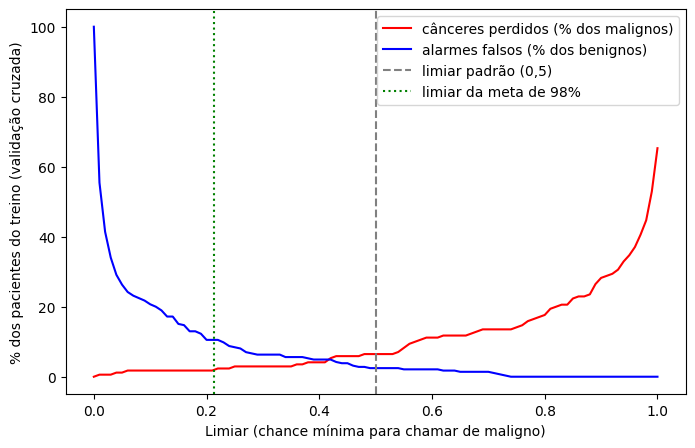

In [27]:
# A curva da troca: para cada limiar de 0 a 1, quantos malignos a validação perde e quantos benignos viram alarme.
limiares = np.linspace(0, 1, 101)                              # linspace: 101 limiares igualmente espaçados (0; 0,01; ...; 1)
malignos = chance_val[y_train.values == 1]                     # chances de validação dos 170 malignos
benignos = chance_val[y_train.values == 0]                     # chances de validação dos 285 benignos
# (malignos < t) marca os perdidos com o limiar t; mean dá a fração deles; * 100 vira porcentagem.
perdidos_pct = [(malignos < t).mean() * 100 for t in limiares]  # % dos malignos perdidos, para cada limiar
alarmes_pct = [(benignos >= t).mean() * 100 for t in limiares]  # % dos benignos com alarme falso, para cada limiar
plt.figure(figsize=(8, 5))                                     # figura retangular
plt.plot(limiares, perdidos_pct, color='red', label='cânceres perdidos (% dos malignos)')  # linha vermelha
plt.plot(limiares, alarmes_pct, color='blue', label='alarmes falsos (% dos benignos)')  # linha azul
# axvline desenha uma linha vertical num ponto do eixo x. linestyle='--' faz tracejada; ':' faz pontilhada.
plt.axvline(0.5, color='gray', linestyle='--', label='limiar padrão (0,5)')  # o limiar usado até aqui
plt.axvline(tabela_limiar.loc['98%', 'limiar'], color='green', linestyle=':', label='limiar da meta de 98%')  # loc pega a linha e a coluna pelo nome
plt.xlabel('Limiar (chance mínima para chamar de maligno)')    # nome do eixo x
plt.ylabel('% dos pacientes do treino (validação cruzada)')    # nome do eixo y
plt.legend()                                                   # mostra a legenda
plt.savefig('figuras/limiar_tradeoff.png', bbox_inches='tight')  # salva o gráfico
plt.show()                                                     # mostra o gráfico

**Leitura do limiar:** com o limiar padrão (0,5), o modelo perde 3 dos 42 cânceres do teste e não dá nenhum alarme falso. Baixando o limiar:

| Meta de recall na validação | Limiar | Cânceres perdidos no teste | Alarmes falsos no teste |
| --- | --- | --- | --- |
| padrão | 0,5 | 3 de 42 | 0 de 72 |
| 98% | 0,21 | 2 de 42 | 6 de 72 (8%) |
| 99% | 0,03 | 0 de 42 | 23 de 72 (32%) |
| 100% | 0,007 | 0 de 42 | 44 de 72 (61%) |

**Os primeiros cânceres saem baratos; os últimos, caros.** Na validação, descer de 0,5 para 0,21 pega 8 cânceres a mais, ao custo de cerca de 3 alarmes falsos por câncer. Descer de 0,21 para 0,03 pega só mais 2, ao custo de mais de 30 alarmes por câncer.

**Por que não dá para zerar os cânceres perdidos?** No treino, um câncer recebeu chance de só 0,007. As medidas dele parecem as de um tumor benigno, como no caso que o SHAP explicou. Para pegá-lo, o modelo teria de chamar de maligno a maior parte dos benignos. Em pacientes novos, nenhum limiar garante zero câncer perdido.

**Qual limiar usar?** Depende de quantos exames extras o hospital aceita para cada câncer a mais encontrado. Essa escolha é da equipe médica, com esta tabela na mesa. Os resultados das seções 8 e 9 usam o limiar padrão, de 0,5.

## 11. Discussão crítica

O modelo pode apoiar a triagem, mas não substitui o médico.

**Como usar na prática:** o modelo entra depois do exame e antes da consulta. Ele mostra a chance de câncer e as medidas que mais pesaram. Os casos com chance alta sobem na fila do médico. Um resultado "benigno" nunca dispensa o paciente: o médico vê todos os exames e decide.

**Limites:** com o limiar padrão, o modelo perdeu 3 de 42 cânceres no teste. Baixar o limiar reduz os cânceres perdidos, mas aumenta os alarmes falsos, e nenhum limiar zera os cânceres perdidos sem muitos alarmes (seção 10). A base é pequena (569 pacientes) e vem de um único centro nos EUA, então precisa ser testada com pacientes do hospital antes do uso.

## 12. Baixar as figuras

O Colab apaga os arquivos quando a sessão fecha. Esta célula junta as figuras num .zip, para o GitHub e o relatório.

In [28]:
import shutil                                                  # shutil: copia, move e compacta arquivos
# make_archive cria o arquivo figuras_parteA.zip com tudo o que está na pasta figuras.
shutil.make_archive('figuras_parteA', 'zip', 'figuras')        # junta os gráficos num .zip
# sys.modules lista as bibliotecas carregadas. 'google.colab' só aparece quando o notebook roda no Colab.
if 'google.colab' in sys.modules:                              # só no Colab (no Docker, pula)
    from google.colab import files                             # ferramenta de download do Colab
    files.download('figuras_parteA.zip')                       # o navegador baixa o .zip para o seu computador